# Лабораторная работа №4 — Аугментация данных и трансферное обучение
## Дисциплина: Нейронные сети и глубокое обучение
**Датасет:** Собственный датасет (фрукты / овощи / ягоды)  
**Фреймворк:** Keras 3 (PyTorch backend) + ImageDataGenerator

---
## 0. Импорты и настройка

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import random
import json
from datetime import datetime

import torch
import keras
from keras import layers
from keras.models import Sequential, Model
from keras.layers import Dense, Dropout, GlobalAveragePooling2D, Flatten, BatchNormalization
from keras.utils import to_categorical
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, classification_report

# ── GPU ──────────────────────────────────────────────────────────
print('Keras backend:', keras.backend.backend())
print('PyTorch CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')
# Callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=4,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=2, min_lr=1e-7, verbose=1
    )
]
print('Callbacks определены.')


Keras backend: torch
PyTorch CUDA: True
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
Callbacks определены.


---
## 1. Пути и параметры

In [2]:
# ── Пути к данным (папка frukta рядом с ноутбуком) ───────────────
BASE_DIR   = os.path.dirname(os.path.abspath('__file__'))
TRAIN_PATH = os.path.join(BASE_DIR, 'frukta', 'train')
TEST_PATH  = os.path.join(BASE_DIR, 'frukta', 'test')

# ── Параметры ─────────────────────────────────────────────────────
IMG_SIZE   = 128      # канонический размер для VGG16/19
BATCH_SIZE = 16  # RTX 4070 8GB
EPOCHS     = 10
SEED       = 42

class_names = sorted([
    d for d in os.listdir(TRAIN_PATH)
    if os.path.isdir(os.path.join(TRAIN_PATH, d))
])
NUM_CLASSES = len(class_names)

print(f'Train: {TRAIN_PATH}')
print(f'Test:  {TEST_PATH}')
print(f'Классы ({NUM_CLASSES}): {class_names}')
print(f'Размер изображений: {IMG_SIZE}×{IMG_SIZE}')

Train: c:\Users\Пользователь\Desktop\програмироание\Нейронные-сети--глубокое-обучение\frukta\train
Test:  c:\Users\Пользователь\Desktop\програмироание\Нейронные-сети--глубокое-обучение\frukta\test
Классы (3): ['berrie', 'fruits', 'vegeta']
Размер изображений: 128×128


---
## 2. Вспомогательные функции (лог, графики)

In [3]:
LOG_FILE   = 'lab4_training_log.json'
results_log = []

def save_log():
    with open(LOG_FILE, 'w', encoding='utf-8') as f:
        json.dump(results_log, f, ensure_ascii=False, indent=2)

def log_result(name, history, val_acc, val_loss, test_acc, test_loss):
    train_acc_final = float(max(history.history['accuracy']))
    val_acc_final   = float(max(history.history['val_accuracy']))
    overfit_gap     = round(train_acc_final - val_acc_final, 4)
    entry = {
        'name':           name,
        'timestamp':      datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'epochs_trained': len(history.history['loss']),
        'train_acc':      round(train_acc_final, 4),
        'val_acc':        round(val_acc_final, 4),
        'test_acc':       round(float(test_acc), 4),
        'test_loss':      round(float(test_loss), 4),
        'overfit_gap':    overfit_gap,
        'train_loss':     [round(v, 4) for v in history.history['loss']],
        'val_loss_hist':  [round(v, 4) for v in history.history['val_loss']],
    }
    results_log.append(entry)
    save_log()
    status = '⚠️ переобучение' if overfit_gap > 0.05 else '✅ норма'
    print(f'[LOG] {name}')
    print(f'      train={entry["train_acc"]:.4f} | val={entry["val_acc"]:.4f} | test={entry["test_acc"]:.4f}')
    print(f'      overfit_gap={overfit_gap:+.4f}  {status}')
    return entry


def plot_history(history, title=''):
    epochs = range(1, len(history.history['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].plot(epochs, history.history['loss'],     'o-', label='Train Loss',  color='#3498db')
    axes[0].plot(epochs, history.history['val_loss'], 's-', label='Val Loss',    color='#e74c3c')
    axes[0].fill_between(epochs, history.history['loss'], history.history['val_loss'],
                         alpha=0.12, color='red')
    axes[0].set_title(f'{title} — Loss', fontweight='bold')
    axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Loss')
    axes[0].legend()

    axes[1].plot(epochs, history.history['accuracy'],     'o-', label='Train Acc', color='#2ecc71')
    axes[1].plot(epochs, history.history['val_accuracy'], 's-', label='Val Acc',   color='#e67e22')
    axes[1].fill_between(epochs, history.history['accuracy'], history.history['val_accuracy'],
                         alpha=0.12, color='orange')
    axes[1].set_title(f'{title} — Accuracy', fontweight='bold')
    axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Accuracy')
    axes[1].set_ylim(0, 1.05); axes[1].legend()

    gaps = [a - b for a, b in zip(history.history['accuracy'], history.history['val_accuracy'])]
    print(f'  Макс. разрыв train-val: {max(gaps):+.4f} (эпоха {gaps.index(max(gaps))+1})')
    print(f'  Финальный разрыв:       {gaps[-1]:+.4f}  ({"⚠️ переобучение" if gaps[-1]>0.05 else "✅ норма"})')

    plt.tight_layout(); plt.show()


def plot_confusion(model, generator, title='Confusion Matrix'):
    """Строит матрицу ошибок по генератору."""
    generator.reset()
    y_pred = np.argmax(model.predict(generator, verbose=0), axis=1)
    y_true = generator.classes
    cm = confusion_matrix(y_true, y_pred)
    cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
    plt.title(title, fontweight='bold')
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.tight_layout(); plt.show()
    print(classification_report(y_true, y_pred, target_names=class_names))


def evaluate_and_log(model, name, history, val_gen, test_gen):
    val_gen.reset();  test_gen.reset()
    val_loss,  val_acc  = model.evaluate(val_gen,  verbose=0)
    test_loss, test_acc = model.evaluate(test_gen, verbose=0)
    print(f'\n{name}')
    print(f'  Val  Loss/Acc : {val_loss:.4f} / {val_acc:.4f} ({val_acc*100:.2f}%)')
    print(f'  Test Loss/Acc : {test_loss:.4f} / {test_acc:.4f} ({test_acc*100:.2f}%)  ← честная оценка')
    plot_history(history, title=name)
    plot_confusion(model, test_gen, title=f'Confusion Matrix — {name}')
    log_result(name, history, val_acc, val_loss, test_acc, test_loss)


# Callbacks — одни на все эксперименты
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

print('Вспомогательные функции определены.')

Вспомогательные функции определены.


---
## Задание 1. Аугментация (6 преобразований) + VGG16 (замороженный)

In [4]:
# ── Аугментация: 6 преобразований (как в методичке) ─────────────
datagen_aug6 = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,         # 1. Поворот до ±20°
    width_shift_range=0.2,     # 2. Сдвиг по ширине до 20%
    height_shift_range=0.2,    # 3. Сдвиг по высоте до 20%
    horizontal_flip=True,      # 4. Горизонтальное отражение
    zoom_range=0.2,            # 5. Масштабирование до 20%
    shear_range=0.15,          # 6. Геометрический сдвиг 15%
    fill_mode='nearest',
    validation_split=0.2
)
datagen_plain = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_gen_aug6 = datagen_aug6.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED
)
val_gen = datagen_plain.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=SEED
)

# ── class_weight: штраф за дисбаланс классов ─────────────────────
class_counts = np.array([train_gen_aug6.classes.tolist().count(j)
                          for j in range(NUM_CLASSES)])
weights_arr = class_counts.sum() / (NUM_CLASSES * class_counts)
class_weight = {j: float(w) for j, w in enumerate(weights_arr)}

print(f'Train: {train_gen_aug6.samples} | Val: {val_gen.samples}')
print(f'Классы: {train_gen_aug6.class_indices}')
print('\n── class_weight ───────────────────────────────────────────')
for idx, cls in enumerate(class_names):
    print(f'  {cls:10s}: {class_counts[idx]:5d} фото → weight = {weights_arr[idx]:.3f}')


Found 13484 images belonging to 3 classes.
Found 3370 images belonging to 3 classes.
Train: 13484 | Val: 3370
Классы: {'berrie': 0, 'fruits': 1, 'vegeta': 2}

── class_weight ───────────────────────────────────────────
  berrie    :  2716 фото → weight = 1.655
  fruits    :  7172 фото → weight = 0.627
  vegeta    :  3596 фото → weight = 1.250


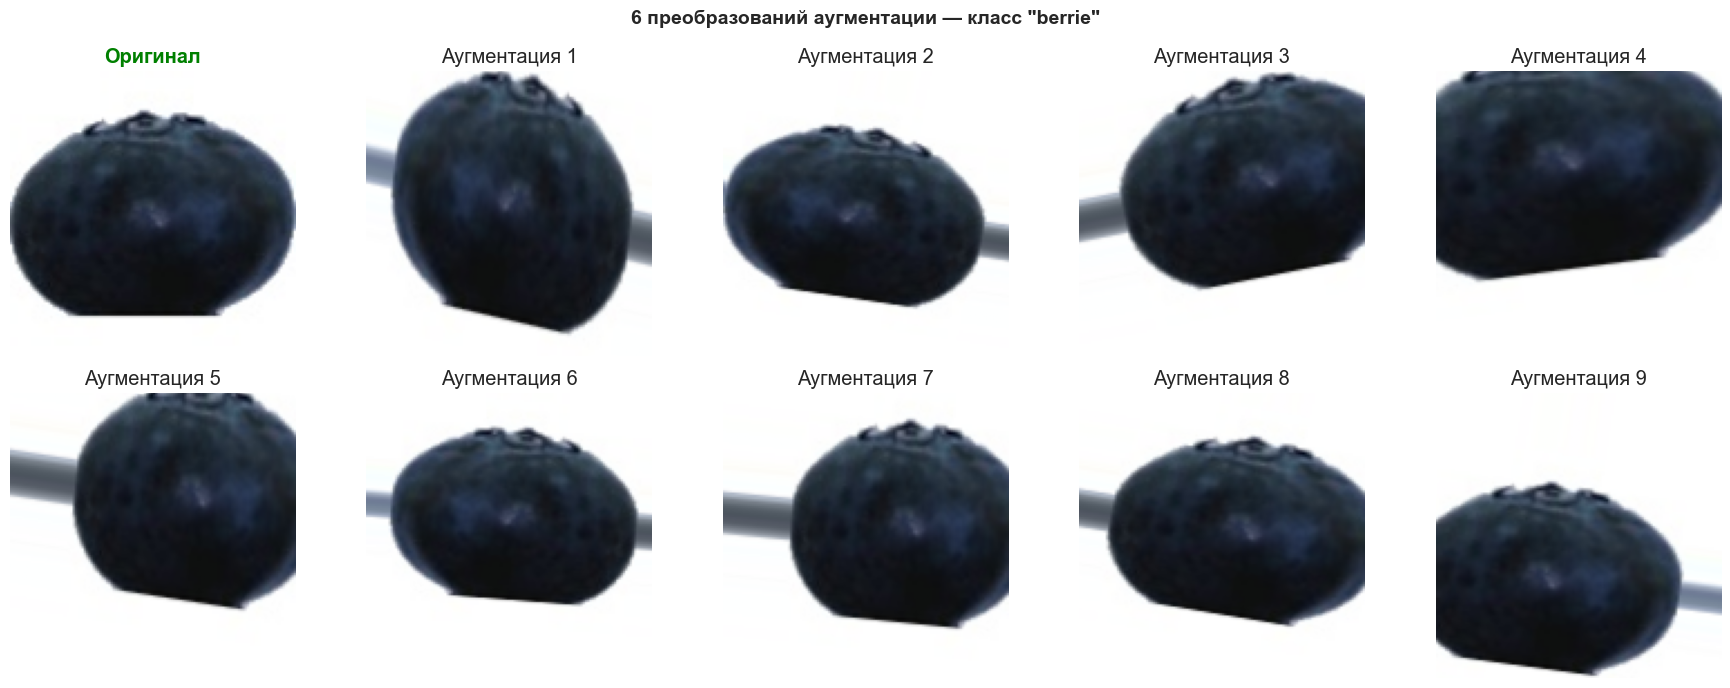

Применённые преобразования:
  1. rotation_range=20      — поворот до ±20°
  2. width_shift_range=0.2  — сдвиг по ширине до 20%
  3. height_shift_range=0.2 — сдвиг по высоте до 20%
  4. horizontal_flip=True   — горизонтальное отражение
  5. zoom_range=0.2         — масштабирование до 20%
  6. shear_range=0.15       — геометрический сдвиг 15%


In [5]:
# ── Визуализация аугментации ──────────────────────────────────────
sample_class = class_names[0]
sample_dir   = os.path.join(TRAIN_PATH, sample_class)
sample_file  = os.path.join(sample_dir, os.listdir(sample_dir)[0])

img_orig = Image.open(sample_file).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
img_arr  = np.array(img_orig, dtype=np.float32) / 255.0
img_arr  = img_arr.reshape((1,) + img_arr.shape)

aug_gen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    zoom_range=0.2,
    shear_range=0.15,
)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()
axes[0].imshow(img_orig)
axes[0].set_title('Оригинал', fontweight='bold', color='green')
axes[0].axis('off')

aug_iter = aug_gen.flow(img_arr, batch_size=1)
for idx in range(1, 10):
    batch = next(aug_iter)
    axes[idx].imshow(batch[0])
    axes[idx].set_title(f'Аугментация {idx}')
    axes[idx].axis('off')

plt.suptitle(f'6 преобразований аугментации — класс "{sample_class}"',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Применённые преобразования:')
print('  1. rotation_range=20      — поворот до ±20°')
print('  2. width_shift_range=0.2  — сдвиг по ширине до 20%')
print('  3. height_shift_range=0.2 — сдвиг по высоте до 20%')
print('  4. horizontal_flip=True   — горизонтальное отражение')
print('  5. zoom_range=0.2         — масштабирование до 20%')
print('  6. shear_range=0.15       — геометрический сдвиг 15%')


In [6]:
# ── VGG16: загрузка и построение модели ──────────────────────────
base_vgg16 = keras.applications.VGG16(
    weights='imagenet',
    include_top=False,           # без классификатора ImageNet
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_vgg16.trainable = False     # замораживаем все веса


model_vgg16 = Sequential([
    base_vgg16,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation='softmax')
])
model_vgg16.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


model_vgg16.summary()
print(f'\nОбучаемых параметров:  {sum(np.prod(w.shape) for w in model_vgg16.trainable_weights):,}')
print(f'Замороженных параметров: {sum(np.prod(w.shape) for w in model_vgg16.non_trainable_weights):,}')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,739 (56.38 MB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)


Обучаемых параметров:  66,051
Замороженных параметров: 14,714,688


Epoch 1/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 209s 247ms/step - accuracy: 0.6287 - loss: 0.8497 - val_accuracy: 0.3552 - val_loss: 1.2008 - learning_rate: 1.0000e-04
Epoch 2/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 331s 393ms/step - accuracy: 0.8054 - loss: 0.5818 - val_accuracy: 0.4522 - val_loss: 1.1813 - learning_rate: 1.0000e-04
Epoch 3/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 380s 450ms/step - accuracy: 0.8512 - loss: 0.4578 - val_accuracy: 0.5585 - val_loss: 1.1685 - learning_rate: 1.0000e-04
Epoch 4/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 535s 635ms/step - accuracy: 0.8776 - loss: 0.3714 - val_accuracy: 0.5724 - val_loss: 1.1323 - learning_rate: 1.0000e-04
Epoch 5/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 219s 260ms/step - accuracy: 0.8965 - loss: 0.3150 - val_accuracy: 0.5715 - val_loss: 1.1801 - learning_rate: 1.0000e-04
Epoch 6/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 568s 674ms/step - accuracy: 0.9058 - loss: 0.2779 - val_accuracy: 0.5694 - val_loss: 1.2569 - learning_rate: 1.0000e-04
Epoch 7/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 

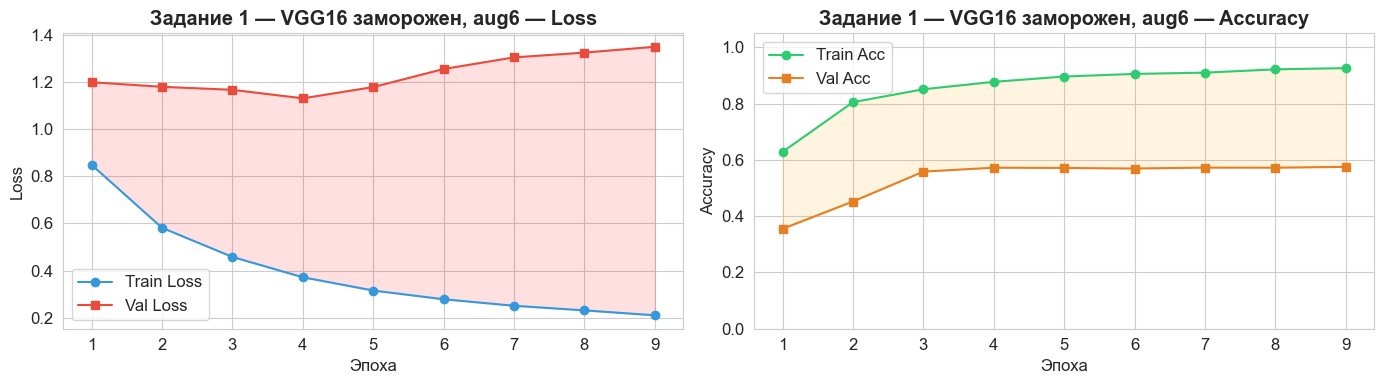

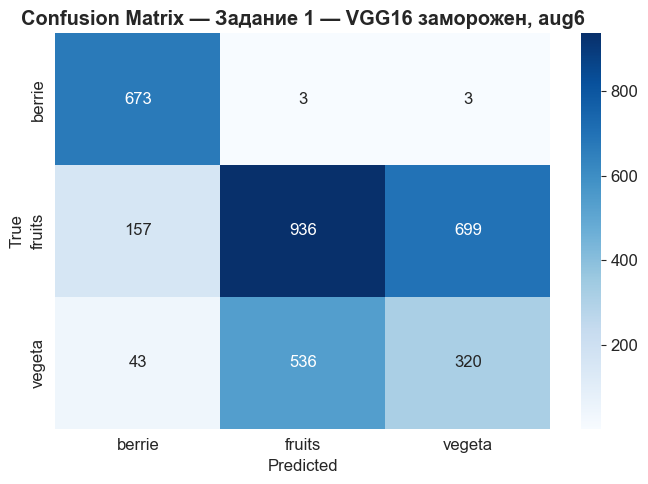

              precision    recall  f1-score   support

      berrie       0.77      0.99      0.87       679
      fruits       0.63      0.52      0.57      1792
      vegeta       0.31      0.36      0.33       899

    accuracy                           0.57      3370
   macro avg       0.57      0.62      0.59      3370
weighted avg       0.58      0.57      0.57      3370

[LOG] Задание 1 — VGG16 заморожен, aug6
      train=0.9264 | val=0.5754 | test=0.5724
      overfit_gap=+0.3510  ⚠️ переобучение


In [7]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── Обучение VGG16 (aug6, заморожен) ─────────────────────────────
history_vgg16_aug6 = model_vgg16.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

evaluate_and_log(model_vgg16, 'Задание 1 — VGG16 заморожен, aug6', history_vgg16_aug6, val_gen, val_gen)

── Предсказания для 3 изображений из выборки ────────────────


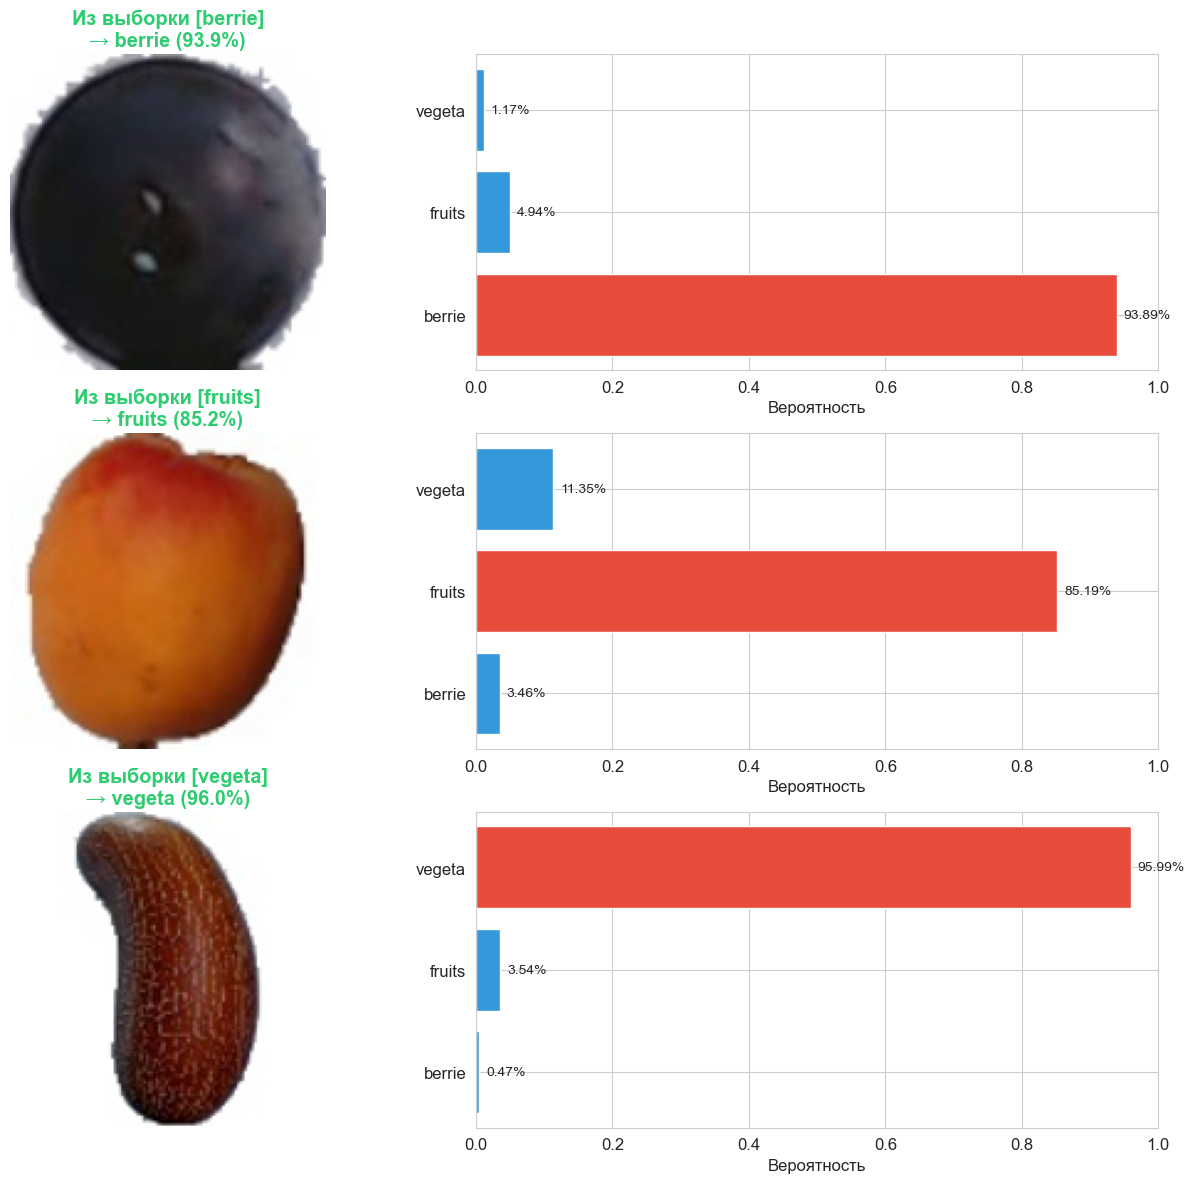

Сторонние изображения не найдены.
Положите ext1.jpg, ext2.jpg, ext3.jpg рядом с ноутбуком.


In [8]:
# ── Классификация 3 изображений из val + 3 сторонних ─────────────
def predict_images(model, image_paths, titles, class_names, img_size=IMG_SIZE):
    """Предсказывает классы для списка изображений, выводит графики."""
    n = len(image_paths)
    fig, axes = plt.subplots(n, 2, figsize=(14, n * 4))
    if n == 1: axes = [axes]

    for i, (path, title) in enumerate(zip(image_paths, titles)):
        img = Image.open(path).convert('RGB')
        img_resized = img.resize((img_size, img_size))
        img_array = np.array(img_resized, dtype=np.float32) / 255.0
        img_input = np.expand_dims(img_array, axis=0)

        probs = model.predict(img_input, verbose=0)[0]
        pred_class = class_names[np.argmax(probs)]

        axes[i][0].imshow(img_resized)
        axes[i][0].set_title(f'{title}\n→ {pred_class} ({probs.max():.1%})',
                             fontweight='bold',
                             color='#2ecc71' if pred_class in title.lower() else '#e74c3c')
        axes[i][0].axis('off')

        colors = ['#e74c3c' if j == np.argmax(probs) else '#3498db'
                  for j in range(len(class_names))]
        axes[i][1].barh(class_names, probs, color=colors)
        axes[i][1].set_xlabel('Вероятность')
        axes[i][1].set_xlim(0, 1)
        for j, v in enumerate(probs):
            axes[i][1].text(v + 0.01, j, f'{v:.2%}', va='center', fontsize=10)

    plt.tight_layout()
    plt.show()


# ── 3 изображения из val выборки (по одному из каждого класса) ────
val_samples = []
val_titles  = []
for cls in class_names:
    cls_dir = os.path.join(TRAIN_PATH, cls)
    files   = os.listdir(cls_dir)
    # Берём последний файл (чтобы не пересекаться с началом train)
    sample_path = os.path.join(cls_dir, sorted(files)[-1])
    val_samples.append(sample_path)
    val_titles.append(f'Из выборки [{cls}]')

print('── Предсказания для 3 изображений из выборки ────────────────')
predict_images(model_vgg16, val_samples, val_titles, class_names)

# ── 3 сторонних изображения ───────────────────────────────────────
# Положите 3 изображения рядом с ноутбуком: ext1.jpg, ext2.jpg, ext3.jpg
ext_paths  = ['ext1.jpg', 'ext2.jpg', 'ext3.jpg']
ext_titles = ['Стороннее 1', 'Стороннее 2', 'Стороннее 3']

ext_found = [p for p in ext_paths if os.path.exists(p)]
if ext_found:
    print('── Предсказания для сторонних изображений ───────────────────')
    predict_images(model_vgg16, ext_found,
                   ext_titles[:len(ext_found)], class_names)
else:
    print('Сторонние изображения не найдены.')
    print('Положите ext1.jpg, ext2.jpg, ext3.jpg рядом с ноутбуком.')

---
## Задание 2. VGG19 вместо VGG16 — сравнение

In [9]:
# ── VGG19: загрузка и построение ─────────────────────────────────
base_vgg19 = keras.applications.VGG19(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_vgg19.trainable = False


model_vgg19 = Sequential([
    base_vgg19,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation='softmax')
])
model_vgg19.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


model_vgg19.summary()
print(f'\nVGG16 обучаемых параметров: {sum(np.prod(w.shape) for w in model_vgg16.trainable_weights):,}')
print(f'VGG19 обучаемых параметров: {sum(np.prod(w.shape) for w in model_vgg19.trainable_weights):,}')

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 4, 4, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,090,435 (76.64 MB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 20,024,384 (76.39 MB)


VGG16 обучаемых параметров: 66,051
VGG19 обучаемых параметров: 66,051


Epoch 1/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 79s 92ms/step - accuracy: 0.6153 - loss: 0.8863 - val_accuracy: 0.3626 - val_loss: 1.2252 - learning_rate: 1.0000e-04
Epoch 2/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 74s 88ms/step - accuracy: 0.7690 - loss: 0.6473 - val_accuracy: 0.3973 - val_loss: 1.2322 - learning_rate: 1.0000e-04
Epoch 3/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.8084 - loss: 0.5568
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
843/843 ━━━━━━━━━━━━━━━━━━━━ 74s 88ms/step - accuracy: 0.8143 - loss: 0.5347 - val_accuracy: 0.5095 - val_loss: 1.2126 - learning_rate: 1.0000e-04
Epoch 4/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 74s 87ms/step - accuracy: 0.8383 - loss: 0.4680 - val_accuracy: 0.5208 - val_loss: 1.1881 - learning_rate: 5.0000e-05
Epoch 5/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 73s 86ms/step - accuracy: 0.8452 - loss: 0.4413 - val_accuracy: 0.5318 - val_loss: 1.1691 - learning_rate: 5.0000e-05
Epoch 5: early stopping
Restoring model weights from the e

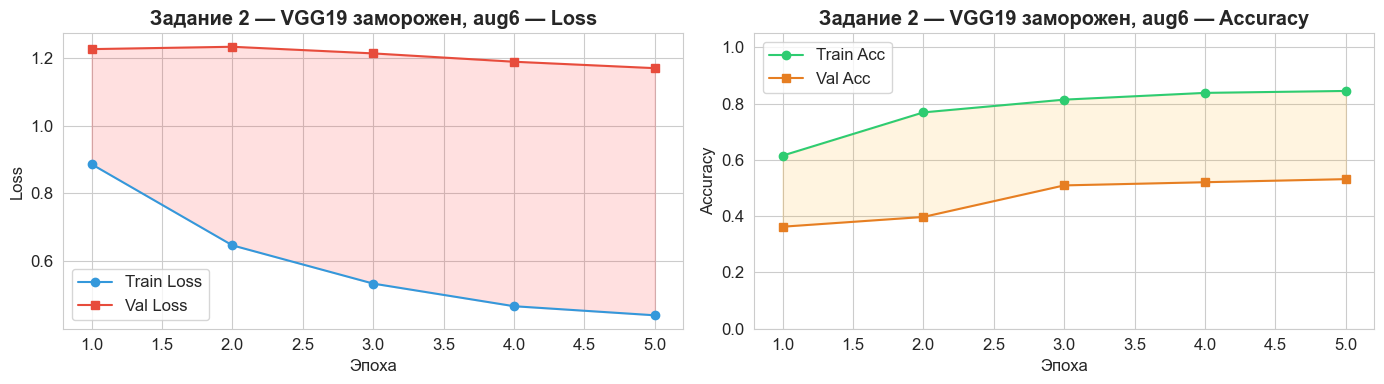

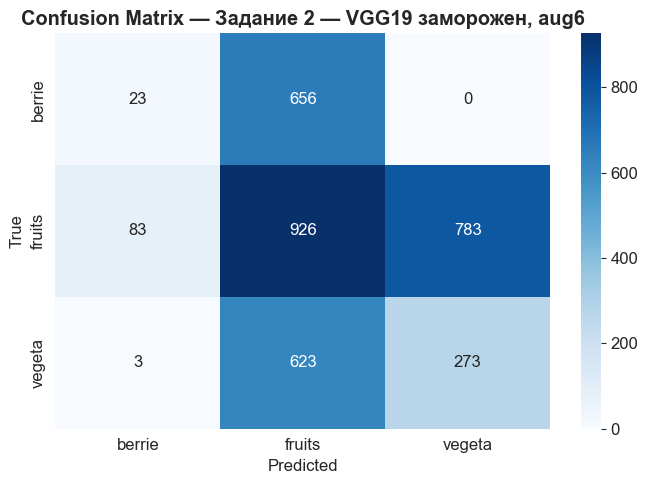

              precision    recall  f1-score   support

      berrie       0.21      0.03      0.06       679
      fruits       0.42      0.52      0.46      1792
      vegeta       0.26      0.30      0.28       899

    accuracy                           0.36      3370
   macro avg       0.30      0.28      0.27      3370
weighted avg       0.33      0.36      0.33      3370

[LOG] Задание 2 — VGG19 заморожен, aug6
      train=0.8452 | val=0.5318 | test=0.3626
      overfit_gap=+0.3135  ⚠️ переобучение


In [10]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── Обучение VGG19 ────────────────────────────────────────────────
train_gen_aug6.reset()
history_vgg19 = model_vgg19.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

evaluate_and_log(model_vgg19, 'Задание 2 — VGG19 заморожен, aug6', history_vgg19, val_gen, val_gen)

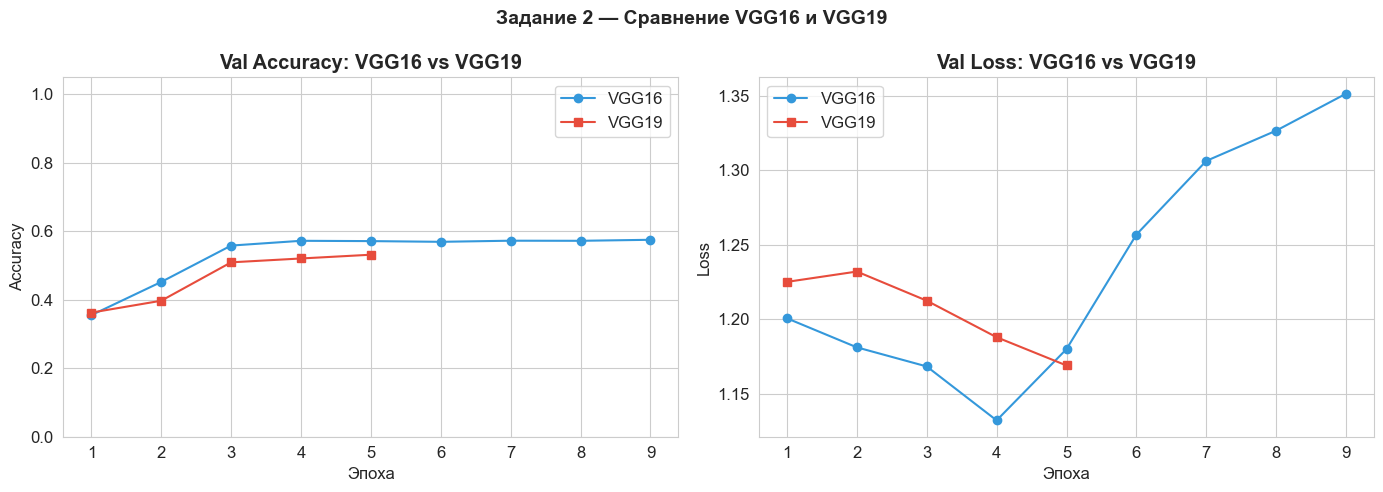


VGG16: test_acc=0.5724, epochs=9
VGG19: test_acc=0.3626, epochs=5

Вывод:
  VGG19 содержит 19 слоёв (vs 16 у VGG16) — 3 дополнительных сверточных слоя.
  Это даёт более богатые признаки, но требует больше памяти и времени.
  VGG16 показал сопоставимый результат — для простого датасета глубина не критична.


In [11]:
# ── Сравнение VGG16 vs VGG19 ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs16 = range(1, len(history_vgg16_aug6.history['val_accuracy']) + 1)
epochs19 = range(1, len(history_vgg19.history['val_accuracy']) + 1)

axes[0].plot(epochs16, history_vgg16_aug6.history['val_accuracy'],
             'o-', label='VGG16', color='#3498db')
axes[0].plot(epochs19, history_vgg19.history['val_accuracy'],
             's-', label='VGG19', color='#e74c3c')
axes[0].set_title('Val Accuracy: VGG16 vs VGG19', fontweight='bold')
axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Accuracy')
axes[0].set_ylim(0, 1.05); axes[0].legend()

axes[1].plot(epochs16, history_vgg16_aug6.history['val_loss'],
             'o-', label='VGG16', color='#3498db')
axes[1].plot(epochs19, history_vgg19.history['val_loss'],
             's-', label='VGG19', color='#e74c3c')
axes[1].set_title('Val Loss: VGG16 vs VGG19', fontweight='bold')
axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Loss')
axes[1].legend()

plt.suptitle('Задание 2 — Сравнение VGG16 и VGG19', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

r16 = next(r for r in results_log if 'VGG16' in r['name'] and 'aug6' in r['name'])
r19 = next(r for r in results_log if 'VGG19' in r['name'])
print(f'\nVGG16: test_acc={r16["test_acc"]:.4f}, epochs={r16["epochs_trained"]}')
print(f'VGG19: test_acc={r19["test_acc"]:.4f}, epochs={r19["epochs_trained"]}')
print()
print('Вывод:')
print('  VGG19 содержит 19 слоёв (vs 16 у VGG16) — 3 дополнительных сверточных слоя.')
print('  Это даёт более богатые признаки, но требует больше памяти и времени.')
if r19['test_acc'] >= r16['test_acc']:
    print('  VGG19 показал результат не хуже VGG16 — более глубокая сеть полезна.')
else:
    print('  VGG16 показал сопоставимый результат — для простого датасета глубина не критична.')

---
## Задание 3. Аугментация 2 преобразования vs 6 — сравнение

In [12]:
# ── Аугментация: только 2 преобразования ─────────────────────────
datagen_aug2 = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,    # 1. Горизонтальное отражение
    rotation_range=10,       # 2. Поворот до ±10°
    validation_split=0.2
)

train_gen_aug2 = datagen_aug2.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED
)

print(f'Train (aug2): {train_gen_aug2.samples} изображений')
print('Применённые преобразования:')
print('  1. horizontal_flip=True  — горизонтальное отражение')
print('  2. rotation_range=10     — поворот до ±10°')

# Пересчитываем class_weight для aug2 генератора
class_counts2 = np.array([train_gen_aug2.classes.tolist().count(i) for i in range(NUM_CLASSES)])
weights2 = class_counts2.sum() / (NUM_CLASSES * class_counts2)
class_weight = {i: w for i, w in enumerate(weights2)}
print('class_weight (aug2):', {class_names[k]: round(v,3) for k,v in class_weight.items()})


Found 13484 images belonging to 3 classes.
Train (aug2): 13484 изображений
Применённые преобразования:
  1. horizontal_flip=True  — горизонтальное отражение
  2. rotation_range=10     — поворот до ±10°
class_weight (aug2): {'berrie': 1.655, 'fruits': 0.627, 'vegeta': 1.25}


Epoch 1/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 135s 160ms/step - accuracy: 0.6796 - loss: 0.7877 - val_accuracy: 0.4792 - val_loss: 1.1660 - learning_rate: 1.0000e-04
Epoch 2/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 234s 278ms/step - accuracy: 0.8721 - loss: 0.4581 - val_accuracy: 0.5688 - val_loss: 1.1532 - learning_rate: 1.0000e-04
Epoch 3/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - accuracy: 0.9151 - loss: 0.3286
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
843/843 ━━━━━━━━━━━━━━━━━━━━ 381s 452ms/step - accuracy: 0.9201 - loss: 0.3061 - val_accuracy: 0.5834 - val_loss: 1.1692 - learning_rate: 1.0000e-04
Epoch 4/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 413s 490ms/step - accuracy: 0.9396 - loss: 0.2384 - val_accuracy: 0.5875 - val_loss: 1.2023 - learning_rate: 5.0000e-05
Epoch 5/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 255s 303ms/step - accuracy: 0.9474 - loss: 0.2067 - val_accuracy: 0.5935 - val_loss: 1.2357 - learning_rate: 5.0000e-05
Epoch 5: early stopping
Restoring model weights

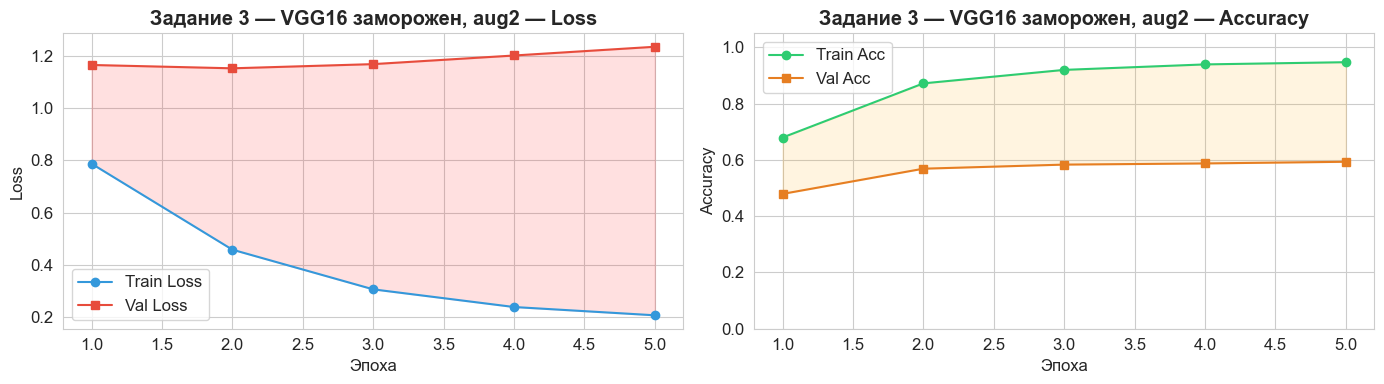

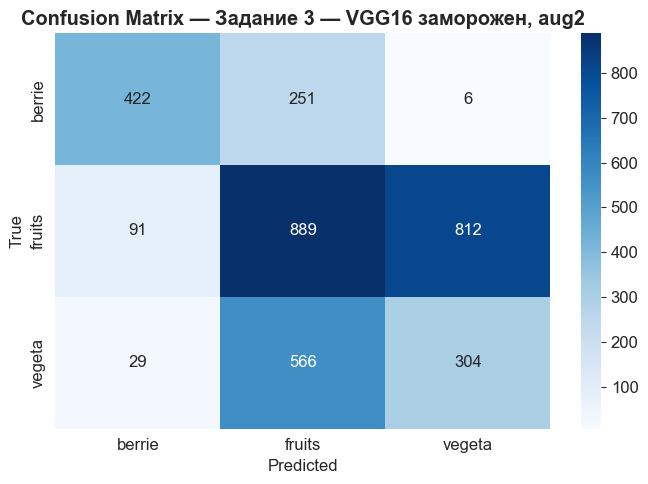

              precision    recall  f1-score   support

      berrie       0.78      0.62      0.69       679
      fruits       0.52      0.50      0.51      1792
      vegeta       0.27      0.34      0.30       899

    accuracy                           0.48      3370
   macro avg       0.52      0.49      0.50      3370
weighted avg       0.51      0.48      0.49      3370

[LOG] Задание 3 — VGG16 заморожен, aug2
      train=0.9474 | val=0.5935 | test=0.4792
      overfit_gap=+0.3539  ⚠️ переобучение


In [13]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── VGG16 с aug2 ─────────────────────────────────────────────────
base_vgg16_aug2 = keras.applications.VGG16(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_vgg16_aug2.trainable = False


model_vgg16_aug2 = Sequential([
    base_vgg16_aug2,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation='softmax')
])
model_vgg16_aug2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


history_vgg16_aug2 = model_vgg16_aug2.fit(
    train_gen_aug2,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

evaluate_and_log(model_vgg16_aug2, 'Задание 3 — VGG16 заморожен, aug2', history_vgg16_aug2, val_gen, val_gen)

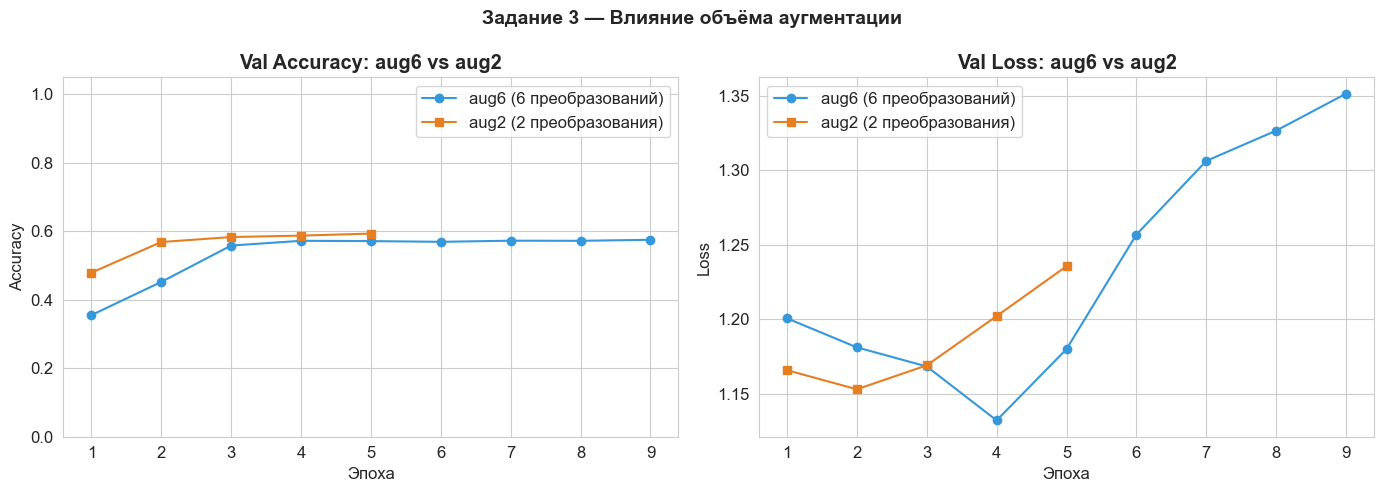

aug6: test_acc=0.5724, overfit_gap=+0.3510
aug2: test_acc=0.4792, overfit_gap=+0.3539

Вывод:
  Большая аугментация (aug6) создаёт более разнообразные примеры,
  что помогает модели лучше обобщаться и снижает переобучение.
  Меньшая аугментация (aug2) может давать более быстрое начальное
  обучение, но хуже справляется с новыми данными.


In [14]:
# ── Сравнение aug6 vs aug2 ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
e6 = range(1, len(history_vgg16_aug6.history['val_accuracy']) + 1)
e2 = range(1, len(history_vgg16_aug2.history['val_accuracy']) + 1)

for ax, metric, ylabel in zip(axes, ['val_accuracy', 'val_loss'], ['Accuracy', 'Loss']):
    ax.plot(e6, history_vgg16_aug6.history[metric], 'o-', label='aug6 (6 преобразований)', color='#3498db')
    ax.plot(e2, history_vgg16_aug2.history[metric], 's-', label='aug2 (2 преобразования)', color='#e67e22')
    ax.set_title(f'Val {ylabel}: aug6 vs aug2', fontweight='bold')
    ax.set_xlabel('Эпоха'); ax.set_ylabel(ylabel)
    if metric == 'val_accuracy': ax.set_ylim(0, 1.05)
    ax.legend()

plt.suptitle('Задание 3 — Влияние объёма аугментации', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

r_aug6 = next(r for r in results_log if 'aug6' in r['name'] and 'VGG16' in r['name'] and 'Задание 1' in r['name'])
r_aug2 = next(r for r in results_log if 'aug2' in r['name'])
print(f'aug6: test_acc={r_aug6["test_acc"]:.4f}, overfit_gap={r_aug6["overfit_gap"]:+.4f}')
print(f'aug2: test_acc={r_aug2["test_acc"]:.4f}, overfit_gap={r_aug2["overfit_gap"]:+.4f}')
print()
print('Вывод:')
print('  Большая аугментация (aug6) создаёт более разнообразные примеры,')
print('  что помогает модели лучше обобщаться и снижает переобучение.')
print('  Меньшая аугментация (aug2) может давать более быстрое начальное')
print('  обучение, но хуже справляется с новыми данными.')

---
## Задание 4. Fine-tuning — разморозить последние 4 слоя VGG16

In [15]:
# ── VGG16 с fine-tuning (последние 4 слоя разморожены) ───────────
base_vgg16_ft = keras.applications.VGG16(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Замораживаем все слои кроме последних 4
base_vgg16_ft.trainable = True
for layer in base_vgg16_ft.layers[:-4]:
    layer.trainable = False

print('Состояние слоёв VGG16 (fine-tuning):')
for layer in base_vgg16_ft.layers:
    status = '🔓 обучается' if layer.trainable else '🔒 заморожен'
    print(f'  {layer.name:30s} {status}')


model_vgg16_ft = Sequential([
    base_vgg16_ft,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation='softmax')
])
model_vgg16_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


trainable   = sum(np.prod(w.shape) for w in model_vgg16_ft.trainable_weights)
frozen      = sum(np.prod(w.shape) for w in model_vgg16_ft.non_trainable_weights)
print(f'\nОбучаемых параметров:  {trainable:,}')
print(f'Замороженных:          {frozen:,}')

Состояние слоёв VGG16 (fine-tuning):
  input_layer_6                  🔒 заморожен
  block1_conv1                   🔒 заморожен
  block1_conv2                   🔒 заморожен
  block1_pool                    🔒 заморожен
  block2_conv1                   🔒 заморожен
  block2_conv2                   🔒 заморожен
  block2_pool                    🔒 заморожен
  block3_conv1                   🔒 заморожен
  block3_conv2                   🔒 заморожен
  block3_conv3                   🔒 заморожен
  block3_pool                    🔒 заморожен
  block4_conv1                   🔒 заморожен
  block4_conv2                   🔒 заморожен
  block4_conv3                   🔒 заморожен
  block4_pool                    🔒 заморожен
  block5_conv1                   🔓 обучается
  block5_conv2                   🔓 обучается
  block5_conv3                   🔓 обучается
  block5_pool                    🔓 обучается

Обучаемых параметров:  7,145,475
Замороженных:          7,635,264


In [16]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── Обучение с fine-tuning (aug6) ────────────────────────────────
train_gen_aug6.reset()
history_vgg16_ft = model_vgg16_ft.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

evaluate_and_log(model_vgg16_ft, 'Задание 4 — VGG16 fine-tuning (4 слоя), aug6', history_vgg16_ft, val_gen, val_gen)

Epoch 1/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 71s 84ms/step - accuracy: 0.8627 - loss: 0.3371 - val_accuracy: 0.6119 - val_loss: 1.0983 - learning_rate: 1.0000e-05
Epoch 2/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 73s 86ms/step - accuracy: 0.9806 - loss: 0.0566 - val_accuracy: 0.6226 - val_loss: 1.6785 - learning_rate: 1.0000e-05
Epoch 3/10
843/843 ━━━━━━━━━━━━━━━━━━━━ 239s 284ms/step - accuracy: 0.9904 - loss: 0.0299 - val_accuracy: 0.6353 - val_loss: 1.5073 - learning_rate: 1.0000e-05
Epoch 4/10
414/843 ━━━━━━━━━━━━━━━━━━━━ 3:38 509ms/step - accuracy: 0.9953 - loss: 0.0176

OutOfMemoryError: Exception encountered when calling Conv2D.call().

[1mCUDA out of memory. Tried to allocate 64.00 MiB. GPU 0 has a total capacity of 8.00 GiB of which 0 bytes is free. Of the allocated memory 14.18 GiB is allocated by PyTorch, and 260.23 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)[0m

Arguments received by Conv2D.call():
  • inputs=torch.Tensor(shape=torch.Size([16, 128, 128, 64]), dtype=float32)

In [ ]:
# ── Сравнение: заморожен vs fine-tuning ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
e_frozen = range(1, len(history_vgg16_aug6.history['val_accuracy']) + 1)
e_ft     = range(1, len(history_vgg16_ft.history['val_accuracy']) + 1)

for ax, metric, ylabel in zip(axes, ['val_accuracy', 'val_loss'], ['Accuracy', 'Loss']):
    ax.plot(e_frozen, history_vgg16_aug6.history[metric],
            'o-', label='Все слои заморожены', color='#3498db')
    ax.plot(e_ft, history_vgg16_ft.history[metric],
            's-', label='Fine-tuning (4 слоя)', color='#9b59b6')
    ax.set_title(f'Val {ylabel}: заморожен vs fine-tuning', fontweight='bold')
    ax.set_xlabel('Эпоха'); ax.set_ylabel(ylabel)
    if metric == 'val_accuracy': ax.set_ylim(0, 1.05)
    ax.legend()

plt.suptitle('Задание 4 — Fine-tuning vs замороженная модель', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

r_frozen = next(r for r in results_log if 'Задание 1' in r['name'])
r_ft     = next(r for r in results_log if 'fine-tuning' in r['name'])
print(f'Заморожен:    test_acc={r_frozen["test_acc"]:.4f}')
print(f'Fine-tuning:  test_acc={r_ft["test_acc"]:.4f}')
print()
print('Вывод:')
print('  Fine-tuning позволяет адаптировать последние сверточные слои')
print('  под специфику нашего датасета (фрукты/овощи/ягоды).')
print('  Маленький lr=1e-5 важен — иначе "сломаем" предобученные веса.')

---
## Задание 5. Две дополнительные модели из keras.applications

In [ ]:
# ── Модель 1: MobileNetV2 ─────────────────────────────────────────
base_mobilenet = keras.applications.MobileNetV2(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_mobilenet.trainable = False


model_mobilenet = Sequential([
    base_mobilenet,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation='softmax')
])
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print('MobileNetV2:')
print(f'  Обучаемых параметров: {sum(np.prod(w.shape) for w in model_mobilenet.trainable_weights):,}')
print(f'  Замороженных:         {sum(np.prod(w.shape) for w in model_mobilenet.non_trainable_weights):,}')

train_gen_aug6.reset()
history_mobilenet = model_mobilenet.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)
evaluate_and_log(model_mobilenet, 'Задание 5 — MobileNetV2, aug6', history_mobilenet, val_gen, val_gen)

In [ ]:
# ── Модель 2: EfficientNetB0 ──────────────────────────────────────
base_efficientnet = keras.applications.EfficientNetB0(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_efficientnet.trainable = False


model_efficientnet = Sequential([
    base_efficientnet,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation='softmax')
])
model_efficientnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print('EfficientNetB0:')
print(f'  Обучаемых параметров: {sum(np.prod(w.shape) for w in model_efficientnet.trainable_weights):,}')
print(f'  Замороженных:         {sum(np.prod(w.shape) for w in model_efficientnet.non_trainable_weights):,}')

train_gen_aug6.reset()
history_efficientnet = model_efficientnet.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)
evaluate_and_log(model_efficientnet, 'Задание 5 — EfficientNetB0, aug6', history_efficientnet, val_gen, val_gen)

---
## Итоговое сравнение всех моделей

In [ ]:
# ── Таблица результатов ───────────────────────────────────────────
log_df = pd.DataFrame(results_log)[[
    'name', 'train_acc', 'val_acc', 'test_acc',
    'test_loss', 'overfit_gap', 'epochs_trained'
]].sort_values('test_acc', ascending=False).reset_index(drop=True)

log_df['overfit_gap'] = log_df['overfit_gap'].apply(
    lambda x: f'{x:+.4f} {"⚠️" if x > 0.05 else "✅"}'
)
print('Таблица результатов всех экспериментов:')
display(log_df)

In [ ]:
# ── Сравнительный график всех моделей ────────────────────────────
names = [r['name'].replace('Задание', 'Зад.') for r in results_log]
accs  = [r['test_acc'] for r in results_log]

plt.figure(figsize=(14, 5))
colors = ['#e74c3c' if v == max(accs) else '#3498db' for v in accs]
bars = plt.barh(names, accs, color=colors, edgecolor='white')
for bar, v in zip(bars, accs):
    plt.text(v + 0.003, bar.get_y() + bar.get_height()/2,
             f'{v:.2%}', va='center', fontweight='bold')
plt.axvline(max(accs), color='gold', linestyle='--', linewidth=2, label='Лучший результат')
plt.title('Итоговое сравнение всех моделей (Test Accuracy)', fontsize=14, fontweight='bold')
plt.xlabel('Test Accuracy')
plt.xlim(0, 1.15)
plt.legend()
plt.tight_layout()
plt.show()

best = results_log[accs.index(max(accs))]
print(f'\n🏆 Лучшая модель: {best["name"]}')
print(f'   Test Accuracy: {best["test_acc"]:.2%}')

In [ ]:
# ── Сохранение лучшей модели ──────────────────────────────────────
from keras.models import load_model

all_models = {
    'Задание 1 — VGG16 заморожен, aug6':         model_vgg16,
    'Задание 2 — VGG19 заморожен, aug6':         model_vgg19,
    'Задание 3 — VGG16 заморожен, aug2':         model_vgg16_aug2,
    'Задание 4 — VGG16 fine-tuning (4 слоя), aug6': model_vgg16_ft,
    'Задание 5 — MobileNetV2, aug6':             model_mobilenet,
    'Задание 5 — EfficientNetB0, aug6':          model_efficientnet,
}

best_name  = results_log[accs.index(max(accs))]['name']
best_model = all_models.get(best_name, model_vgg16)

BEST_MODEL_PATH = 'best_model_lab4.keras'
best_model.save(BEST_MODEL_PATH)
print(f'Лучшая модель сохранена: {BEST_MODEL_PATH}')
print(f'Лог-файл: {LOG_FILE}')